In [1]:
import numpy as np

In [2]:
var_a = np.array([0.3, 1.0]).mean()

In [3]:
print(var_a)

0.65


In [4]:
import seaborn as sns

In [5]:
df = sns.load_dataset("diamonds")

In [6]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [12]:
carats = np.array([0.23, 0.31, 0.70, 1.10, 2.00])

In [13]:
print(carats.mean(), carats.min(), carats.max())

0.868 0.23 2.0


In [14]:
print(carats[carats > 0.5])

[0.7 1.1 2. ]


In [16]:
import pandas as pd

In [17]:
stones = pd.DataFrame({
    "stone": ["A", "B", "C"],
    "carat": [0.23, 0.90, 2.29],
    "price": [326, 2757, 18823]
})

In [18]:
print(stones["price"].mean())

7302.0


In [19]:
print(stones[stones["price"] > 1000])

  stone  carat  price
1     B   0.90   2757
2     C   2.29  18823


In [20]:
print(df.shape)

(53940, 10)


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [22]:
print(df["cut"].value_counts())

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64


In [23]:
print((df[["x", "y", "z"]] == 0).sum())

x     8
y     7
z    20
dtype: int64


In [24]:
print(df[["x", "y", "z"]].max())

x    10.74
y    58.90
z    31.80
dtype: float64


In [25]:
print(df.groupby("cut", observed=True)["price"].mean().round(0))

cut
Ideal        3458.0
Premium      4584.0
Very Good    3982.0
Good         3929.0
Fair         4359.0
Name: price, dtype: float64


In [26]:
print(df.groupby("cut", observed=True)["carat"].mean().round(2))

cut
Ideal        0.70
Premium      0.89
Very Good    0.81
Good         0.85
Fair         1.05
Name: carat, dtype: float64


In [27]:
import matplotlib.pyplot as plt

<Axes: xlabel='carat', ylabel='price'>

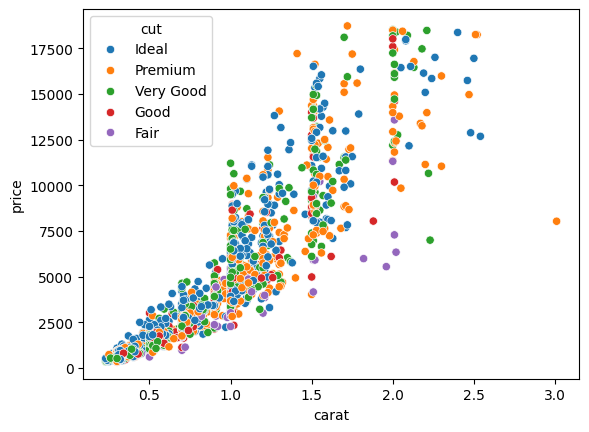

In [28]:
sns.scatterplot(data=df.sample(2000, random_state=1),x="carat", y="price", hue="cut")

In [29]:
plt.show()

In [30]:
print(df["carat"].corr(df["price"]).round(2))

0.92


In [31]:
ok = ((df[["x", "y", "z"]] > 0) & (df[["x", "y", "z"]] < 20)).all(axis=1)

In [32]:
df = df[ok]

In [33]:
print(df.shape)

(53917, 10)


In [34]:
df=df.sample(10000, random_state=42)

In [35]:
for col in ["cut", "color", "clarity"]:
    df[col] = df[col].cat.codes

In [36]:
df["luxury"] = (
    df["price"] >= 10000).astype(int)

In [37]:
print(df["luxury"].mean())

0.0945


In [38]:
df[df["luxury"] == 1]["carat"].min()

1.0

In [39]:
df.groupby("color")["luxury"].mean()

,luxury
color,
0,0.052590
1,0.063806
2,0.081382
3,0.091663
4,0.115686
5,0.176346
6,0.148148


In [40]:
df.groupby("luxury")["carat"].mean()

,carat
luxury,
0,0.694075
1,1.748370


In [41]:
features = ["carat", "cut", "color", "clarity", "depth", "table"]

In [42]:
X = df[features]
Y = df["luxury"]

In [43]:
print(X.shape)

(10000, 6)


In [45]:
from sklearn.model_selection import (train_test_split)

In [46]:
X_tr, X_te, Y_tr, Y_te = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y)

In [47]:
print(len(X_tr), len(X_te))

8000 2000


In [48]:
from sklearn.tree import (DecisionTreeClassifier)

In [49]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)

In [50]:
model.fit(X_tr, Y_tr)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [51]:
print(model.score(X_te, Y_te))

0.9665
